## Embeddings


Embeddings são representações numéricas que traduzem dados de alta dimensão, como texto, imagens ou áudio, em vetores de dimensão reduzida. Esses vetores preservam relações semânticas ou contextuais do dado original, permitindo que informações complexas sejam manipuladas de forma mais eficiente em cálculos e algoritmos.

No caso de textos, por exemplo, um embedding transforma palavras, frases ou documentos em números de tal forma que palavras com significados semelhantes fiquem próximas no espaço vetorial. Por exemplo, podemos dizer que a palavra homem está para a palavra rei, da mesma forma que a palavra mulher está para a palavra rainha. Esses significados semânticos servem como ferramenta para que possamos obter contextos dentro de situações em que precisamos dele.


In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from langchain_openai import OpenAIEmbeddings
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.document_loaders import PyPDFLoader

from dotenv import load_dotenv
import os

from tqdm import tqdm

load_dotenv()

OPENAI_API_KEY = os.getenv("OPENAI_API_KEY")

In [9]:
embedding_size = 1536
embedding_model = "text-embedding-3-small"
embeddings = OpenAIEmbeddings(model=embedding_model, dimensions=embedding_size)

## Carregando os dados:

Instanciando o [`PyPDFLoader`](https://python.langchain.com/docs/integrations/document_loaders/pypdfloader/), temos um objeto de loader do lanchain. No momento em que essa classe é instanciada, colocamos o caminho do arquivo PDF que queremos ler, e o objeto resultante tem um método chamado .load(). 
Esse método permite a leitura do arquivo PDF, e o resultado é o texto presente no PDF dentro de um objeto "Document", que faz parte da biblioteca do langchain e é a base dessa dinâmica de leitura de documentos da biblioteca.

In [10]:
file_path_ed_financeira = "../data/educacao_financeira.pdf"
file_path_historia = "../data/historia.pdf"
loader_historia = PyPDFLoader(file_path_historia)
loader_ed_financeira = PyPDFLoader(file_path_ed_financeira)
pages_historia = loader_historia.load()
pages_ed_financeira = loader_ed_financeira.load()

In [11]:
# Concatenante todo o conteudo em uma string só

all_content_pages_historia = "\n\n".join([page.page_content for page in pages_historia])
all_content_pages_ed_financeira = "\n\n".join([page.page_content for page in pages_ed_financeira])

## Text Splitter

Utilizamos uma técnica de text splitting para quebrar os textos em chunks (fragmentos menores). Isso é interessante no nosso contexto porque facilita o processamento e a análise de textos longos em tarefas como classificação ou geração de respostas. 

[`Recursive Text Splitter`](https://python.langchain.com/docs/how_to/recursive_text_splitter/).

In [12]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=5000,
    chunk_overlap=1500,
    length_function=len,
    is_separator_regex=False,
)

In [13]:
##Aqui, temos como output uma lista de documents, onde cada document é um chunk do documento original
chunks_historia = text_splitter.split_documents(pages_historia)
chunks_ed_financeira = text_splitter.split_documents(pages_ed_financeira)

In [14]:
len(chunks_historia), len(chunks_ed_financeira)

(234, 183)

## Injetando a conversação

In [39]:
import json

with open("../data/conversation/conversation_data_2.json", "r", encoding="utf-8") as f:
    loaded_content = json.load(f)   

In [40]:
loaded_content[:5]

[{'summary': 'Persona 1 expressa fascínio pela história da humanidade, destacando a Revolução Industrial como um ponto de virada significativo.',
  'persona': 'Persona 1',
  'message': 'Você já parou para pensar em como a história da humanidade é fascinante? Por exemplo, a Revolução Industrial foi um ponto de virada incrível, não acha?'},
 {'summary': 'A conversa gira em torno da história da humanidade, com foco na Revolução Industrial. Persona 1 destaca a importância desse evento como um ponto de virada fascinante, enquanto Persona 2 concorda, enfatizando o impacto profundo que a Revolução Industrial teve na produção, sociedade e economia, moldando o mundo moderno.',
  'persona': 'Persona 2',
  'message': 'Com certeza! A Revolução Industrial não só transformou a maneira como produzimos bens, mas também teve um impacto profundo na sociedade e na economia. É interessante como essas mudanças moldaram o mundo moderno.'},
 {'summary': 'A conversa entre as duas personas gira em torno da his

In [41]:
chunks_conversation = []
for item in loaded_content:
    chunks_conversation.append(item['summary'])
    # chunks_conversation.append(item['message'])


In [42]:
len(chunks_conversation)

58

## Criando embeddings

Aqui, nós criamos os embeddings utilizando o [`OpenAIEmbeddings`](https://python.langchain.com/docs/integrations/text_embedding/openai/), e transformamos esses embeddings em arrays do numpy, que otimiza o uso desses embeddings para cálculos.

Criamos embeddings para os textos de história e educação financeira separadamente, e depois concatenamos (juntamos) os dois tipos de embeddings em um array só com todos os embeddings

In [43]:
vectors_conversation = np.array(embeddings.embed_documents([chunk for chunk in chunks_conversation]))

In [44]:
vectors_historia = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_historia]))

In [45]:
vectors_ed_financeira = np.array(embeddings.embed_documents([chunk.page_content for chunk in chunks_ed_financeira]))

In [46]:
all_vectors = np.concatenate([vectors_conversation, vectors_historia, vectors_ed_financeira], axis=0)

In [47]:
vectors_conversation.shape, vectors_ed_financeira.shape, vectors_historia.shape, all_vectors.shape

((58, 1536), (183, 1536), (234, 1536), (475, 1536))

## Reduzindo a dimensionalidade

Embeddings possuem uma quantidade significativa de dimensões. Para facilitar a compreensão, pense nas três dimensões que observamos no espaço ao nosso redor: altura, largura e profundidade. Com elas, conseguimos descrever a posição de qualquer objeto no espaço. Agora, imagine lidar com mais de 1000 dimensões. É impossível visualizar ou compreender intuitivamente esse espaço, mesmo que ele carregue significados importantes.

Para lidar com essa complexidade, utilizamos técnicas de redução de dimensionalidade, que permitem diminuir o número de dimensões sem perder as características principais dos dados. Uma dessas técnicas amplamente utilizadas é o t-SNE (t-Distributed Stochastic Neighbor Embedding). Essa técnica é capaz de projetar dados de alta dimensão em um espaço de dimensões menores, geralmente 2 ou 3, preservando as relações de proximidade entre os pontos no espaço original.

Não é necessário nos preocuparmos com os detalhes matemáticos dessa técnica, pois bibliotecas como o sklearn.manifold já oferecem implementações eficientes. Podemos utilizá-la para reduzir os nossos embeddings para 2 dimensões, permitindo que eles sejam visualizados em um plano 2D.

In [48]:
from sklearn.manifold import TSNE

tsne = TSNE(n_components=2, random_state=42)
all_vectors_tsne = tsne.fit_transform(all_vectors)

In [49]:
len(vectors_conversation), len(vectors_historia), len(vectors_ed_financeira), len(all_vectors_tsne)

(58, 234, 183, 475)

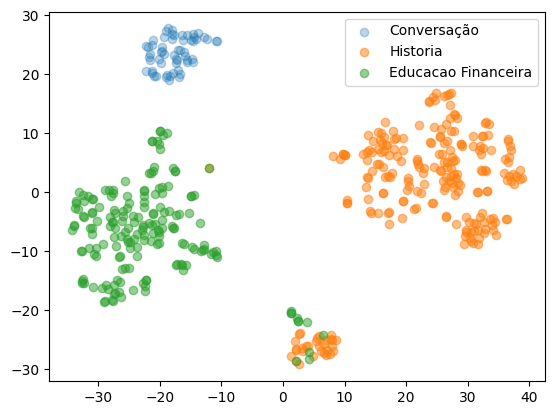

In [50]:
plt.scatter(all_vectors_tsne[:len(vectors_conversation), 0], all_vectors_tsne[:len(vectors_conversation), 1], label="Conversação", alpha=0.3)

plt.scatter(all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 0], all_vectors_tsne[len(vectors_conversation):len(vectors_historia) + len(vectors_conversation), 1], label="Historia", alpha=0.5)
plt.scatter(all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 0], all_vectors_tsne[len(vectors_historia) + len(vectors_conversation):, 1], label="Educacao Financeira", alpha=0.5)
plt.legend()
plt.show()

In [51]:
centroid_historia = np.mean(vectors_historia, axis=0)
centroid_ed_financeira = np.mean(vectors_ed_financeira, axis=0)

In [52]:
# import cos similarity from sklearn
from sklearn.metrics.pairwise import cosine_similarity

# Compare all summary vectors to centroids
similarity_to_historia = cosine_similarity(vectors_conversation, centroid_historia.reshape(1, -1))
similarity_to_ed_financeira = cosine_similarity(vectors_conversation, centroid_ed_financeira.reshape(1, -1))

In [53]:
content_and_similarities = []
for i in range(len(chunks_conversation)):
    content_and_similarities.append({
        "chunk": chunks_conversation[i],
        "similarity_to_historia": similarity_to_historia[i, 0],
        "similarity_to_ed_financeira": similarity_to_ed_financeira[i, 0]
    })

In [54]:
df = pd.DataFrame(content_and_similarities)

In [55]:
df.sort_values(by="similarity_to_ed_financeira", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_ed_financeira
31,A conversa entre as duas personas gira em torn...,0.365226,0.659451
35,A conversa entre as duas personas foca na impo...,0.386852,0.648943
32,A conversa entre as duas personas gira em torn...,0.366975,0.641585
33,A conversa entre as duas personas gira em torn...,0.382142,0.638237
34,A conversa entre as duas personas gira em torn...,0.399881,0.631577
36,A conversa entre as duas personas gira em torn...,0.385627,0.627925
40,A conversa entre as duas personas foca na impo...,0.394515,0.625070
39,A conversa entre as duas personas gira em torn...,0.407145,0.617436
27,A conversa entre as duas personas foca na impo...,0.351469,0.615697
37,A conversa entre as duas personas gira em torn...,0.380030,0.614173


In [56]:
df.sort_values(by="similarity_to_historia", ascending=False).head(10)

,chunk,similarity_to_historia,similarity_to_ed_financeira
2,A conversa entre as duas personas gira em torn...,0.418517,0.400432
38,A conversa entre as duas personas gira em torn...,0.417451,0.600136
42,A conversa entre as duas personas gira em torn...,0.415561,0.544742
39,A conversa entre as duas personas gira em torn...,0.407145,0.617436
34,A conversa entre as duas personas gira em torn...,0.399881,0.631577
51,A conversa entre as duas personas gira em torn...,0.399343,0.553612
9,A conversa entre as duas personas começa com u...,0.398516,0.542905
43,A conversa entre as duas personas gira em torn...,0.398360,0.584712
47,A conversa entre as duas personas gira em torn...,0.396272,0.565396
40,A conversa entre as duas personas foca na impo...,0.394515,0.625070


In [57]:
example_ed_fin = df.sort_values(by="similarity_to_ed_financeira", ascending=False).head(10)['chunk'].values
for x in example_ed_fin:
    print(x)
    print("-----")

A conversa entre as duas personas gira em torno da importância do planejamento para a aposentadoria e da educação financeira. Elas concordam que começar a poupar cedo é crucial devido ao poder dos juros compostos e que pequenas contribuições podem crescer significativamente ao longo do tempo. A discussão também aborda a responsabilidade compartilhada entre escolas e pais na educação financeira, destacando a importância de ensinar as crianças sobre orçamento e economia doméstica. Além disso, mencionam o conceito de "gastar com propósito", que envolve alinhar os gastos com valores e objetivos pessoais, evitando gastos impulsivos.
-----
A conversa entre as duas personas foca na importância da educação financeira, destacando que é uma responsabilidade compartilhada entre escolas e pais. Eles discutem como envolver crianças em discussões sobre orçamento pode ajudar a entender o valor do dinheiro. O conceito de "gastar com propósito" é mencionado como uma forma de alinhar gastos com valores 

In [58]:
example_ed_hist = df.sort_values(by="similarity_to_historia", ascending=False).head(10)['chunk'].values
for x in example_ed_hist:
    print(x)
    print("-----")

A conversa entre as duas personas gira em torno da história da humanidade, com foco na Revolução Industrial. Elas discutem como esse período foi um ponto de virada significativo, transformando a produção de bens e impactando profundamente a sociedade e a economia. A conversa também destaca a importância contínua da inovação tecnológica como um motor de mudança no mundo moderno.
-----
A conversa entre as duas personas gira em torno de educação financeira, com foco no conceito de "gastar com propósito". Persona 1 introduz a ideia de alinhar os gastos com valores e objetivos pessoais para evitar compras impulsivas e focar no que realmente importa. Persona 2 concorda e destaca que isso pode ajudar a economizar mais, contribuindo para alcançar a liberdade financeira. Eles discutem a viabilidade da liberdade financeira, concordando que é um objetivo realista, mas que requer planejamento, disciplina e educação financeira. Ambos reconhecem que a definição de liberdade financeira pode variar en